###

<h1 style="text-align: center;">
Privacy-Preserving Risk-Based Authentication Using Homomorphic Encryption
</h1>

###

**Motivation**: Account fraud is a common security threat, especially in online services where attackers may attempt to access user accounts using stolen credentials. To detect suspicious login attempts, many companies use Risk-Based Authentication (RBA) systems, which assign a risk score to each login based on factors such as the user’s previous login history, location, device, browser, and access time. However, this process often requires storing and processing sensitive user data in plaintext. Therefore, applying homomorphic encryption can improve privacy by allowing risk evaluation while keeping user information protected.

**Background**

- **Homomorphic Encryption (HE):** a cryptographic technique that allows computations to be performed directly on encrypted data. In this notebook, HE is considered only for the inference stage.

- **Risk-Based Authentication (RBA):** an authentication approach that assigns a risk score to each login attempt based on contextual information such as previous login history, location, device, browser, IP address, and access time. If the risk score is high, the system can require additional verification or block the login attempt.


**Pipeline**

| # | Section | Description |
|---|---------|-------------|
| 1 | Dataset Analysis | Schema, class balance, temporal and geographic characterisation |
| 2 | Feature Engineering | Pair-based delta features: haversine distance, speed, device fingerprint |
| 3 | Train / Test Split | Temporal 80/20 split — prevents temporal data leakage |
| 4 | Balancing Strategy | `scale_pos_weight` for XGBoost — native, no data modification |
| 5 | Model Training | Plaintext XGBClassifier + Concrete-ML FHE XGBClassifier |
| 6 | Validation | Stratified K-Fold CV, ROC/PR curves, feature importance |
| 7 | Testing | Plaintext / FHE-simulate / FHE-execute inference comparison |
| 8 | Artifact Export | Persist models for FastAPI deployment |


In [1]:
# Imports & Configuration
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110

In [2]:
# Paths
DATASET_CSV = (
    Path('/dataset/rba-dataset.csv')
    if Path('/dataset').exists()
    else Path('../database/anomaly-detection-dataset/rba-dataset.csv')
)
MODELS_DIR = (
    Path('/models')
    if Path('/models').exists()
    else Path('../service_provider_app/app/modules/anomaly_detection/models')
)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Reproducibility 
SEED = 42
np.random.seed(SEED)

## II. Dataset Analysis

The RBA dataset contains synthesised login-attempt records from a large-scale Norwegian single-sign-on (SSO) service (February 2020 - February 2021).  Features span four categories:
 - network identity (IP, country, ASN)
 - device fingerprint (OS, browser, device type)
 - temporal context (timestamp)
 - authentication outcome


#### 1. Load Dataset

Because this notebook is run inside a container with limited memory capacity (24 GB), it is not possible to load all features from the beginning.
We chose to discard the following features:
- User Agent String
- Round-Trip Time (96% of the samples are missing this value)

In [4]:
# Load dataset
LOAD_COLS = [
    'Login Timestamp', 'User ID',
    'Country', 'Region', 'City',
    'Browser Name and Version', 'OS Name and Version', 'Device Type',
    'ASN', 'IP Address', 'Is Attack IP', 'Login Successful', 'Is Account Takeover',
]

NROWS = None
print('Loading dataset ...')
t0 = time.time()
df_raw = pd.read_csv(DATASET_CSV, nrows=NROWS, low_memory=False, usecols=LOAD_COLS)
elapsed = time.time() - t0
print(f'Loaded {len(df_raw):,} rows x {df_raw.shape[1]} columns in {elapsed:.1f}s')
print(f'Memory (raw strings)   : {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

# Convert high-cardinality string columns to category dtype.
# Category stores each unique string once; the column itself is a compact integer index.
# Saves ~8-10 GB on 31 M rows, keeping peak allocation well under 20 GB.
for col in ['Country', 'Region', 'City',
            'Browser Name and Version', 'OS Name and Version', 'Device Type',
            'IP Address']:
    df_raw[col] = df_raw[col].astype('category')

print(f'Memory (after category): {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
df_raw.head(5)

Loading dataset ...
Loaded 31,269,264 rows x 13 columns in 131.6s
Memory (raw strings)   : 17,640 MB
Memory (after category): 4,013 MB


,Login Timestamp,User ID,IP Address,Country,Region,City,ASN,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,2020-02-03 12:43:30.772,-4324475583306591935,10.0.65.171,NO,-,-,29695,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,2020-02-03 12:43:43.549,-4324475583306591935,194.87.207.6,AU,-,-,60117,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2020-02-03 12:43:55.873,-3284137479262433373,81.167.144.58,NO,Vestland,Urangsvag,29695,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,2020-02-03 12:43:56.180,-4324475583306591935,170.39.78.152,US,-,-,393398,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,2020-02-03 12:43:59.396,-4618854071942621186,10.0.0.47,US,Virginia,Ashburn,398986,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


#### 2. Missing Values

For most features, all values are available. The exceptions are:

- Region: 0.15% missing values
- City: 0.03% missing values

Observation: For the Round-Trip Time feature, 96% of the values were missing. Therefore, it was decided not to load this feature at all in order to save memory.

In [5]:
info = pd.DataFrame({
    'dtype':    df_raw.dtypes.astype(str),
    'non_null': df_raw.notnull().sum(),
    'null_%':   (df_raw.isnull().mean() * 100).round(2),
    'nunique':  df_raw.nunique(),
})
print('=== Schema & Missing Values ===')
print(info.to_string())

=== Schema & Missing Values ===
                             dtype  non_null  null_%   nunique
Login Timestamp             object  31269264    0.00  31269085
User ID                      int64  31269264    0.00   4304857
IP Address                category  31269264    0.00   3512330
Country                   category  31269264    0.00       229
Region                    category  31221855    0.15      2638
City                      category  31260674    0.03     38885
ASN                          int64  31269264    0.00     12955
Browser Name and Version  category  31269264    0.00      4549
OS Name and Version       category  31269264    0.00       653
Device Type               category  31267738    0.00         5
Login Successful              bool  31269264    0.00         2
Is Attack IP                  bool  31269264    0.00         2
Is Account Takeover           bool  31269264    0.00         2


#### 3. Class balance

The RBA dataset is highly imbalanced.

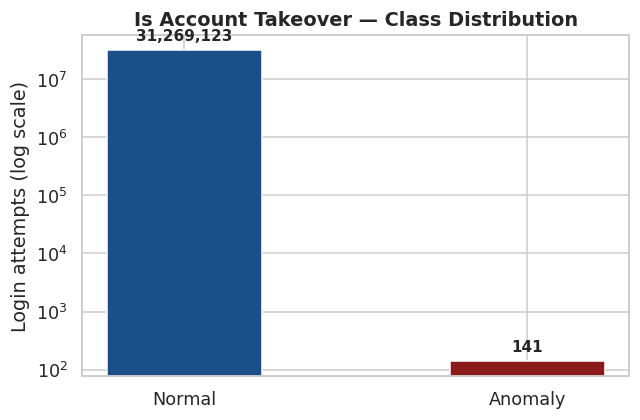

Total logins : 31,269,264
Unique users : 4,304,857



,Count,Share (%)
Class,,
Normal,"31,269,123",99.999549%
Anomaly,141,0.000451%
Total,"31,269,264",100.000000%


Selected label  : Is Account Takeover
Imbalance ratio : 1 : 221,766


In [6]:
# Class balance
from IPython.display import display

n_total = len(df_raw)
n_tak   = df_raw["Is Account Takeover"].isin([True, "True"]).sum()
n_users = df_raw["User ID"].nunique()

LABEL_COL = "Is Account Takeover"
n_pos     = n_tak
n_neg     = n_total - n_tak

# Bar chart — log Y so the tiny anomaly bar is visible alongside 22 M normal logins
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Normal", "Anomaly"],
    [n_neg, n_pos],
    color=["#1a4f8a", "#8b1a1a"],
    width=0.45,
)
ax.set_yscale("log")
ax.set_ylabel("Login attempts (log scale)")
ax.set_title("Is Account Takeover — Class Distribution", fontweight="bold")
for bar, val in zip(bars, [n_neg, n_pos]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, val * 1.3,
        f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold",
    )
plt.tight_layout()
plt.show()

# Summary table — Is Account Takeover only
print(f"Total logins : {n_total:,}")
print(f"Unique users : {n_users:,}")
print()
tbl = pd.DataFrame([
    {"Class": "Normal",  "Count": n_neg,   "Share (%)": round(n_neg / n_total * 100, 6)},
    {"Class": "Anomaly", "Count": n_pos,   "Share (%)": round(n_pos / n_total * 100, 6)},
    {"Class": "Total",   "Count": n_total, "Share (%)": 100.0},
]).set_index("Class")
tbl["Count"]     = tbl["Count"].apply(lambda x: f"{x:,}")
tbl["Share (%)"] = tbl["Share (%)"].apply(lambda x: f"{x:.6f}%")
display(tbl)

print(f"Selected label  : Is Account Takeover")
print(f"Imbalance ratio : 1 : {int(n_neg / max(n_pos, 1)):,}")

#### 4. Temporal Distribution of Attacks

Because the memory constraints caused multiple issues, the temporal distribution of attacks was analyzed in order to decide which part of the dataset could be removed optimally.

The goal was to preserve all positive samples, since there were only a few of them anyway. It was observed that after 2020-11, there were no other samples classified as attacks. Therefore, all samples later than 2020-11 were removed.

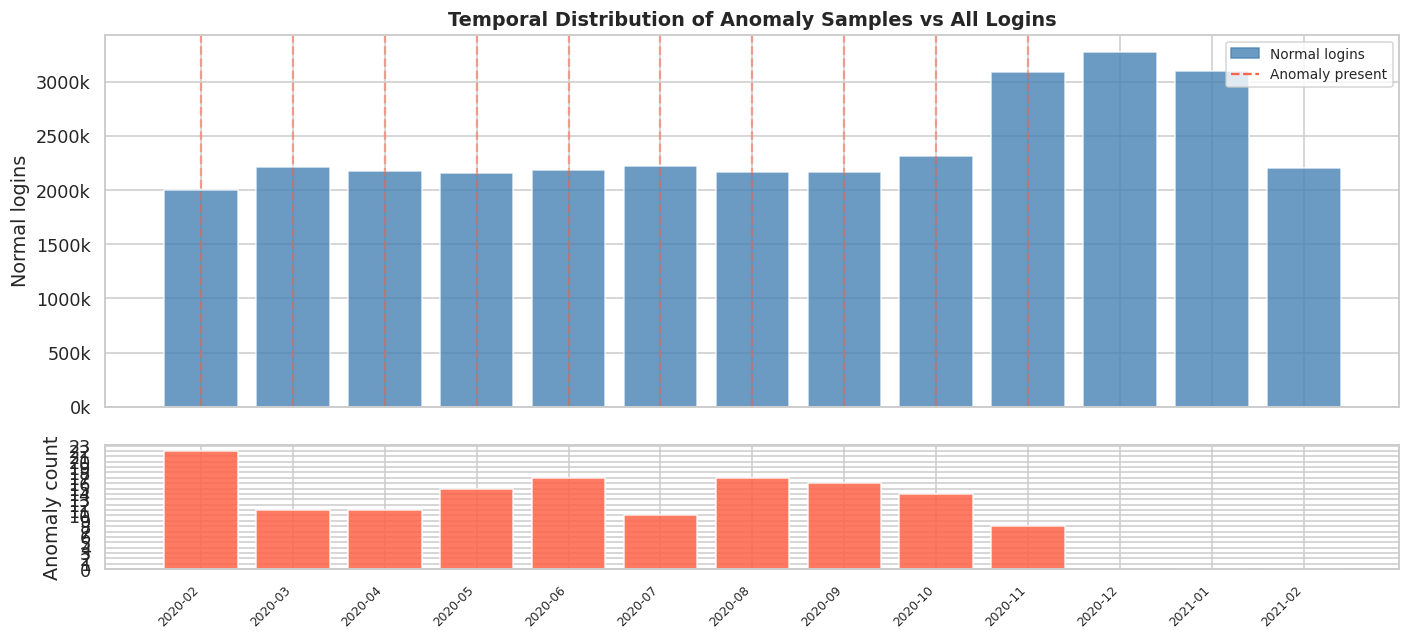

Months containing anomalies:
  2020-02:  22 anomalies  |  dataset position: first 6.4%
  2020-03:  11 anomalies  |  dataset position: first 13.5%
  2020-04:  11 anomalies  |  dataset position: first 20.4%
  2020-05:  15 anomalies  |  dataset position: first 27.3%
  2020-06:  17 anomalies  |  dataset position: first 34.3%
  2020-07:  10 anomalies  |  dataset position: first 41.4%
  2020-08:  17 anomalies  |  dataset position: first 48.4%
  2020-09:  16 anomalies  |  dataset position: first 55.3%
  2020-10:  14 anomalies  |  dataset position: first 62.7%
  2020-11:   8 anomalies  |  dataset position: first 72.6%


In [7]:
# Temporal position of anomaly samples

ts_all      = pd.to_datetime(df_raw['Login Timestamp'], errors='coerce')
is_anomaly  = df_raw['Is Account Takeover'].isin([True, 'True'])

monthly_normal  = ts_all[~is_anomaly].dt.to_period('M').value_counts().sort_index()
monthly_anomaly = ts_all[ is_anomaly].dt.to_period('M').value_counts().sort_index()

all_months   = monthly_normal.index.union(monthly_anomaly.index).sort_values()
normal_vals  = monthly_normal.reindex(all_months,  fill_value=0)
anomaly_vals = monthly_anomaly.reindex(all_months, fill_value=0)
x            = np.arange(len(all_months))
xlabels      = [str(m) for m in all_months]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

ax1.bar(x, normal_vals.values, color='steelblue', alpha=0.8)
ax1.set_ylabel('Normal logins')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v/1e3)}k'))
ax1.set_title('Temporal Distribution of Anomaly Samples vs All Logins', fontweight='bold')
for i, v in enumerate(anomaly_vals.values):
    if v > 0:
        ax1.axvline(i, color='tomato', alpha=0.5, linestyle='--', linewidth=1.5)
ax1.legend(handles=[
    plt.Rectangle((0,0),1,1, color='steelblue', alpha=0.8, label='Normal logins'),
    plt.Line2D([0],[0], color='tomato', linestyle='--', lw=1.5, label='Anomaly present'),
], fontsize=9)

ax2.bar(x, anomaly_vals.values, color='tomato', alpha=0.85)
ax2.set_ylabel('Anomaly count')
ax2.set_xticks(x)
ax2.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
ax2.set_yticks(range(0, int(anomaly_vals.max()) + 2))

plt.tight_layout()
plt.show()

print('Months containing anomalies:')
for m, n, a in zip(all_months, normal_vals, anomaly_vals):
    if a > 0:
        pct_dataset = (normal_vals[:list(all_months).index(m)+1].sum()
                       + anomaly_vals[:list(all_months).index(m)+1].sum()) / (normal_vals.sum() + anomaly_vals.sum()) * 100
        print(f'  {m}: {a:3d} anomalies  |  dataset position: first {pct_dataset:.1f}%')

In [8]:
# Trim dataset to rows up to end of 2020-11 (last month containing anomalies)
import gc

_ts    = pd.to_datetime(df_raw['Login Timestamp'], errors='coerce')
before = len(df_raw)
df_raw = df_raw[_ts < '2020-12-01'].reset_index(drop=True)
del _ts
gc.collect()

after = len(df_raw)
print(f'Rows before cutoff  : {before:>12,}')
print(f'Rows after  cutoff  : {after:>12,}  (removed {before - after:,} — {(before-after)/before*100:.1f}%)')
print(f'Anomalies retained  : {df_raw["Is Account Takeover"].isin([True, "True"]).sum()}')

Rows before cutoff  :   31,269,264
Rows after  cutoff  :   22,694,974  (removed 8,574,290 — 27.4%)
Anomalies retained  : 141


#### 5. Geographic & Device Characterisation


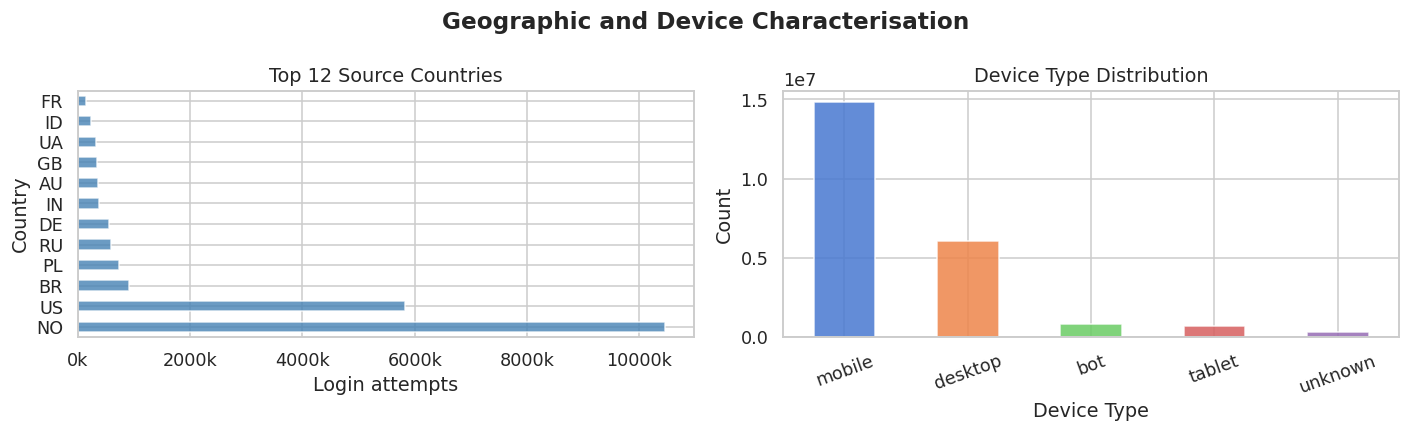

In [9]:
# Geographic & device characterisation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

top_c = df_raw['Country'].value_counts().head(12)
top_c.plot.barh(ax=axes[0], color='steelblue', alpha=0.8)
axes[0].set_title('Top 12 Source Countries')
axes[0].set_xlabel('Login attempts')
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x/1e3)}k'))

dt = df_raw['Device Type'].fillna('unknown').value_counts()
dt.plot.bar(ax=axes[1], color=sns.color_palette('muted', len(dt)), alpha=0.85)
axes[1].set_title('Device Type Distribution')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Geographic and Device Characterisation', fontweight='bold')
plt.tight_layout()
plt.show()

#### 6. Login Frequncy per user


=== Login frequency per user ===
count    3536462.00
mean           6.42
std         4957.53
min            1.00
25%            1.00
50%            2.00
75%            4.00
max      9322666.00
Users with >=2 logins : 2,114,776  (59.8%)
Users with >=5 logins : 782,946  (22.1%)
Note: only users with >=2 logins generate pair features.


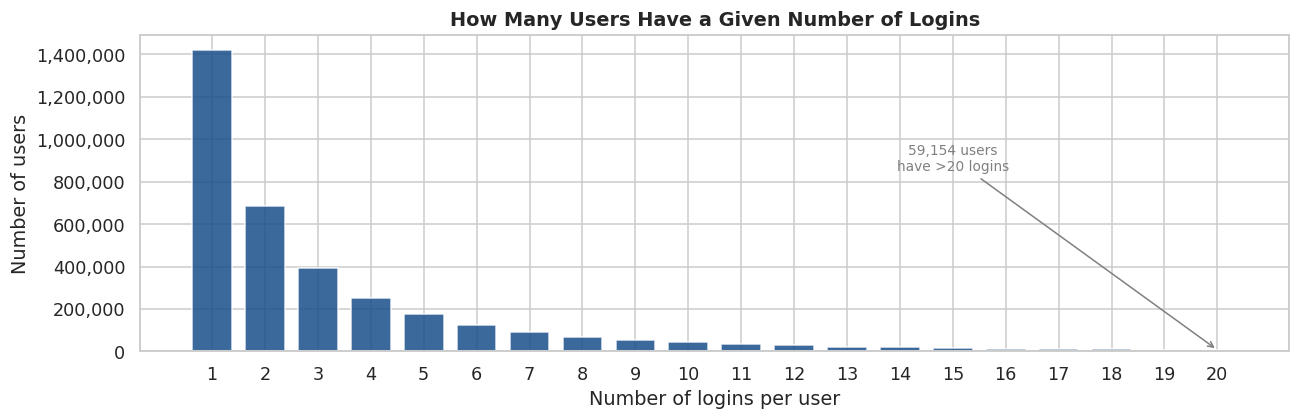

In [10]:
# Login frequency per user
# X = number of logins, Y = number of users with that count — shows the distribution clearly.
lpu = df_raw.groupby('User ID').size()

print('=== Login frequency per user ===')
print(lpu.describe().round(2).to_string())
print(f'Users with >=2 logins : {(lpu >= 2).sum():,}  ({(lpu >= 2).mean()*100:.1f}%)')
print(f'Users with >=5 logins : {(lpu >= 5).sum():,}  ({(lpu >= 5).mean()*100:.1f}%)')
print('Note: only users with >=2 logins generate pair features.')

CAP     = 20
vc      = lpu.value_counts().sort_index()
vc_show = vc[vc.index <= CAP]
n_tail  = int(vc[vc.index > CAP].sum())

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(vc_show.index, vc_show.values, color='#1a4f8a', alpha=0.85, width=0.75)
ax.set_xlabel('Number of logins per user')
ax.set_ylabel('Number of users')
ax.set_title('How Many Users Have a Given Number of Logins', fontweight='bold')
ax.set_xticks(range(1, CAP + 1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
if n_tail > 0:
    tail_label = f'{n_tail:,} users\nhave >{CAP} logins'
    ax.annotate(
        tail_label,
        xy=(CAP, vc_show.iloc[-1]), xytext=(CAP - 5, vc_show.max() * 0.6),
        arrowprops=dict(arrowstyle='->', color='gray'),
        fontsize=9, color='gray', ha='center',
    )
plt.tight_layout()
plt.show()



## 2. Feature Engineering - Consecutive Login Pairs

### Rationale
A single login event carries no temporal context.  Impossible travel can only be detected by
comparing a login against the **immediately preceding login of the same user**.  This requires:
1. Sorting each user's history by `Login Timestamp`
2. Shifting the previous row's values into the current row (pandas `groupby + shift`)
3. Computing pair-level delta features

The first login per user is discarded (no predecessor available).

### Feature Set
| Feature | Type | Description |
|---------|------|-------------|
| `distance_km` | continuous | Great-circle distance between login countries (haversine on centroids) |
| `speed_kmh` | continuous | Implied travel speed; physically capped at 50 000 km/h |
| `time_delta_h` | continuous | Elapsed hours since previous login |
| `same_country` | binary | Country unchanged from previous login (1 = same) |
| `same_city` | binary | City unchanged |
| `same_browser` | binary | Browser + version unchanged |
| `same_os` | binary | OS + version unchanged |
| `same_device` | binary | Device type unchanged |
| `hour_of_day` | ordinal | Hour of login (0-23) |
| `is_weekend` | binary | Weekend login flag |

Geographic distance is approximated via **country centroids** — a deliberate simplification
that avoids an external geolocation database while preserving the signal for cross-country travel.

In [13]:
# Country centroids + vectorised haversine
COUNTRY_CENTROIDS = {
    'AF':(33.93,67.71),'AL':(41.15,20.17),'DZ':(28.03,1.66),
    'AO':(-11.2,17.87),'AR':(-38.42,-63.62),'AT':(47.52,14.55),
    'AU':(-25.27,133.78),'AZ':(40.14,47.58),'BA':(43.92,17.67),
    'BD':(23.68,90.36),'BE':(50.5,4.47),'BG':(42.73,25.49),
    'BO':(-16.29,-63.59),'BR':(-14.24,-51.93),'BY':(53.71,28.0),
    'CA':(56.13,-106.35),'CH':(46.82,8.23),'CL':(-35.68,-71.54),
    'CN':(35.86,104.2),'CO':(4.57,-74.3),'CZ':(49.82,15.47),
    'DE':(51.17,10.45),'DK':(56.26,9.5),'DO':(18.74,-70.16),
    'EC':(-1.83,-78.18),'EE':(58.6,25.01),'EG':(26.82,30.8),
    'ES':(40.46,-3.75),'ET':(9.15,40.49),'FI':(61.92,25.75),
    'FR':(46.23,2.21),'GB':(55.38,-3.44),'GE':(42.32,43.36),
    'GH':(7.95,-1.02),'GR':(39.07,21.82),'HK':(22.4,114.11),
    'HR':(45.1,16.45),'HU':(47.16,19.5),'ID':(-0.79,113.92),
    'IE':(53.41,-8.24),'IL':(31.05,34.85),'IN':(20.59,78.96),
    'IQ':(33.22,43.68),'IR':(32.43,53.69),'IS':(64.96,-19.02),
    'IT':(41.87,12.57),'JP':(36.2,138.25),'KE':(-0.02,37.91),
    'KR':(35.91,127.77),'KZ':(48.02,66.92),'LT':(55.17,23.88),
    'LV':(56.88,24.6),'MA':(31.79,-7.09),'MD':(47.41,28.37),
    'MX':(23.63,-102.55),'MY':(4.21,101.98),'NG':(9.08,8.68),
    'NL':(52.13,5.29),'NO':(60.47,8.47),'NZ':(-40.9,174.89),
    'PE':(-9.19,-75.02),'PH':(12.88,121.77),'PK':(30.38,69.35),
    'PL':(51.92,19.15),'PT':(39.4,-8.22),'RO':(45.94,24.97),
    'RS':(44.02,21.01),'RU':(61.52,105.32),'SA':(23.89,45.08),
    'SE':(60.13,18.64),'SG':(1.35,103.82),'SK':(48.67,19.7),
    'TH':(15.87,100.99),'TN':(33.89,9.54),'TR':(38.96,35.24),
    'TW':(23.7,121.0),'UA':(48.38,31.17),'US':(37.09,-95.71),
    'UZ':(41.38,64.59),'VN':(14.06,108.28),'ZA':(-30.56,22.94),
}
_LAT = {k: v[0] for k, v in COUNTRY_CENTROIDS.items()}
_LON = {k: v[1] for k, v in COUNTRY_CENTROIDS.items()}

def haversine_vectorised(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat / 2) ** 2
         + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2))
         * np.sin(dlon / 2) ** 2)
    return 2.0 * R * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))

# Sanity check
for c1, c2, expected in [('NO','AU',14200), ('NO','US',7500), ('NO','NO',0)]:
    d = haversine_vectorised(
        np.array([_LAT[c1]]), np.array([_LON[c1]]),
        np.array([_LAT[c2]]), np.array([_LON[c2]]))[0]
    print(f'  {c1} -> {c2}: {d:.0f} km  (expected ~{expected} km)')

  NO -> AU: 14342 km  (expected ~14200 km)
  NO -> US: 7187 km  (expected ~7500 km)
  NO -> NO: 0 km  (expected ~0 km)


In [14]:
# 2b. Pair-feature engineering
#
# Extended feature set:
#   + is_attack_ip        -- current login from a known attack IP
#   + prev_is_attack_ip   -- previous login from a known attack IP
#   + same_region         -- same region/state as previous login
#   + same_asn            -- same autonomous system (VPN/proxy signal)
#   + prev_login_failed   -- previous login attempt was unsuccessful
#   + same_ip             -- exact same IP address as previous login
#   + same_ip_prefix      -- same /24 subnet (tolerates DHCP address rotation)
FEATURE_COLS = [
    'distance_km', 'speed_kmh', 'time_delta_h',
    'same_country', 'same_region', 'same_city',
    'same_browser', 'same_os', 'same_device', 'same_asn',
    'hour_of_day', 'is_weekend',
    'is_attack_ip', 'prev_is_attack_ip', 'prev_login_failed',
    'same_ip', 'same_ip_prefix',
]
MAX_SPEED_KMH = 50_000

def engineer_pair_features(df: pd.DataFrame, label_col: str) -> pd.DataFrame:
    df = df.copy()
    df['Login Timestamp'] = pd.to_datetime(df['Login Timestamp'], errors='coerce')
    df[label_col] = df[label_col].isin([True, 'True']).astype(np.int8)
    df = df.sort_values(['User ID', 'Login Timestamp']).reset_index(drop=True)

    grp = df.groupby('User ID', sort=False)
    for col in ['Login Timestamp', 'Country', 'Region', 'City',
                'Browser Name and Version', 'OS Name and Version', 'Device Type',
                'ASN', 'IP Address', 'Is Attack IP', 'Login Successful']:
        df[f'_p_{col}'] = grp[col].shift(1)

    df = df.dropna(subset=['_p_Login Timestamp']).copy()

    elapsed_s = (df['Login Timestamp'] - df['_p_Login Timestamp']
                 ).dt.total_seconds().clip(lower=0)
    df['time_delta_h'] = elapsed_s / 3600.0
    df['hour_of_day']  = df['Login Timestamp'].dt.hour
    df['is_weekend']   = (df['Login Timestamp'].dt.dayofweek >= 5).astype(np.int8)

    df['same_country'] = (df['Country'] == df['_p_Country']).astype(np.int8)
    df['same_region']  = (df['Region']  == df['_p_Region']).astype(np.int8)
    df['same_city']    = (df['City']    == df['_p_City']).astype(np.int8)
    df['same_browser'] = (
        df['Browser Name and Version'] == df['_p_Browser Name and Version']
    ).astype(np.int8)
    df['same_os'] = (
        df['OS Name and Version'] == df['_p_OS Name and Version']
    ).astype(np.int8)
    df['same_device'] = (
        df['Device Type'] == df['_p_Device Type']
    ).astype(np.int8)
    df['same_asn'] = (df['ASN'] == df['_p_ASN']).astype(np.int8)

    df['is_attack_ip']      = df['Is Attack IP'].isin([True, 'True']).astype(np.int8)
    df['prev_is_attack_ip'] = df['_p_Is Attack IP'].isin([True, 'True']).astype(np.int8)
    df['prev_login_failed'] = (~df['_p_Login Successful'].isin([True, 'True'])).astype(np.int8)

    # IP-based features: convert category to str for reliable cross-category comparison
    ip_cur  = df['IP Address'].astype(str)
    ip_prev = df['_p_IP Address'].astype(str)
    df['same_ip']        = (ip_cur == ip_prev).astype(np.int8)
    df['same_ip_prefix'] = (
        ip_cur.str.rsplit('.', n=1).str[0] == ip_prev.str.rsplit('.', n=1).str[0]
    ).astype(np.int8)

    lat_cur  = df['Country'].map(_LAT).values.astype(float)
    lon_cur  = df['Country'].map(_LON).values.astype(float)
    lat_prev = df['_p_Country'].map(_LAT).values.astype(float)
    lon_prev = df['_p_Country'].map(_LON).values.astype(float)

    dist = haversine_vectorised(lat_cur, lon_cur, lat_prev, lon_prev)
    df['distance_km'] = np.where(np.isnan(lat_cur) | np.isnan(lat_prev), 0.0, dist)
    df['speed_kmh'] = np.where(
        df['time_delta_h'] > 0,
        np.minimum(df['distance_km'] / df['time_delta_h'], MAX_SPEED_KMH),
        np.where(df['distance_km'] > 0, float(MAX_SPEED_KMH), 0.0),
    )

    return df.drop(columns=[c for c in df.columns if c.startswith('_p_')])

In [15]:
# 2c. Apply & validate
#
# All loaded columns are used in feature engineering, so no intermediate
# df_input copy is needed — pass df_raw directly to halve peak allocation.

import gc

print(f'df_raw  : {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB  ({df_raw.shape[1]} columns)')
print('\nEngineering pair features ...')
t0 = time.time()
df = engineer_pair_features(df_raw, LABEL_COL)
del df_raw
gc.collect()
print(f'Done in {time.time()-t0:.1f}s  |  shape: {df.shape}')

n_pos = int((df[LABEL_COL] == 1).sum())
n_neg = int((df[LABEL_COL] == 0).sum())
n_tot = len(df)
print(f'\nPost-engineering class distribution:')
print(f'  Normal  : {n_neg:>10,}  ({n_neg/n_tot*100:.3f}%)')
print(f'  Anomaly : {n_pos:>10,}  ({n_pos/n_tot*100:.4f}%)')

if n_pos < 10:
    raise RuntimeError(
        f'Only {n_pos} anomalies after pair engineering. '
        f'Set NROWS=None to load the full dataset.')

print('\nFeature statistics:')
df[FEATURE_COLS].describe().round(3)

df_raw  : 2,546 MB  (12 columns)

Engineering pair features ...
Done in 27.3s  |  shape: (19158512, 29)

Post-engineering class distribution:
  Normal  : 19,158,419  (100.000%)
  Anomaly :         93  (0.0005%)

Feature statistics:


,distance_km,speed_kmh,time_delta_h,same_country,same_region,same_city,same_browser,same_os,same_device,same_asn,hour_of_day,is_weekend,is_attack_ip,prev_is_attack_ip,prev_login_failed,same_ip,same_ip_prefix
count,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,1.915851e+07,19158512.0,19158512.0
mean,2.871793e+03,1.817164e+04,2.408920e+02,6.260000e-01,4.970000e-01,4.830000e-01,3.720000e-01,4.490000e-01,6.870000e-01,5.130000e-01,1.227400e+01,2.600000e-01,9.000000e-02,9.000000e-02,6.130000e-01,0.0,0.0
std,4.436197e+03,2.404598e+04,6.980160e+02,4.840000e-01,5.000000e-01,5.000000e-01,4.830000e-01,4.970000e-01,4.640000e-01,5.000000e-01,5.644000e+00,4.390000e-01,2.860000e-01,2.860000e-01,4.870000e-01,0.0,0.0
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
50%,0.000000e+00,0.000000e+00,5.000000e-03,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.300000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.0,0.0
75%,7.186855e+03,5.000000e+04,4.949200e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.700000e+01,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.0,0.0
max,1.989040e+04,5.000000e+04,7.227927e+03,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.300000e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.0,0.0


In [16]:
# df_raw and df_input are already freed inside cc09.
# At this point only df (engineered, ~3 GB) remains in memory.
print(f'df memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB  |  shape: {df.shape}')

df memory: 1710 MB  |  shape: (19158512, 29)


=== Mean feature values: normal vs anomaly ===
                   Normal (mean)  Anomaly (mean)  Ratio A/N
distance_km             2871.791        3330.318       1.16
speed_kmh              18171.712        3234.669       0.18
time_delta_h             240.889         724.153       3.01
same_country               0.626           0.226       0.36
same_region                0.497           0.312       0.63
same_city                  0.483           0.312       0.65
same_browser               0.372           0.269       0.72
same_os                    0.449           0.462       1.03
same_device                0.687           0.634       0.92
same_asn                   0.513           0.183       0.36
hour_of_day               12.274          13.194       1.07
is_weekend                 0.260           0.301       1.16
is_attack_ip               0.090           0.548       6.09
prev_is_attack_ip          0.090           0.215       2.39
prev_login_failed          0.613           0.237     

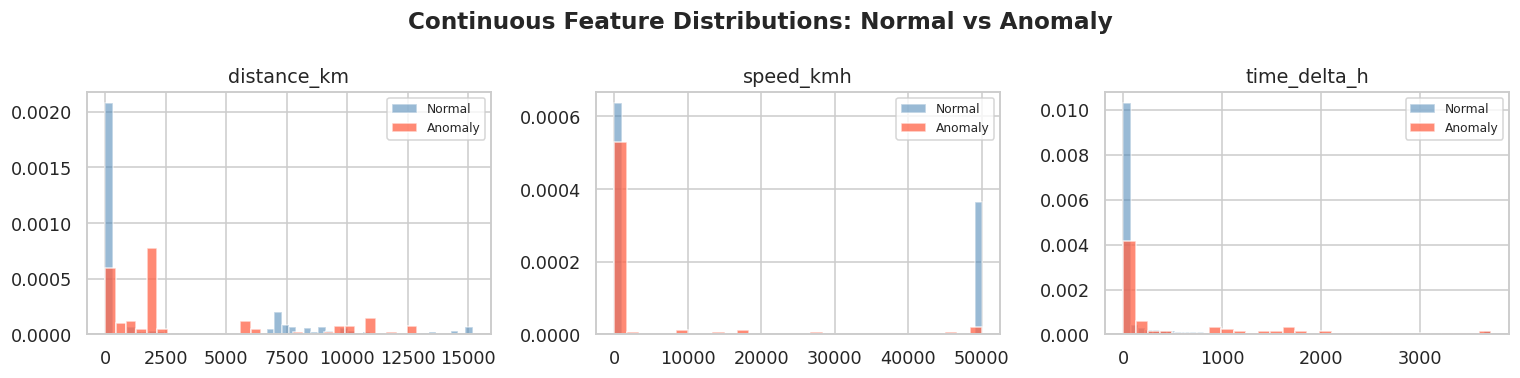

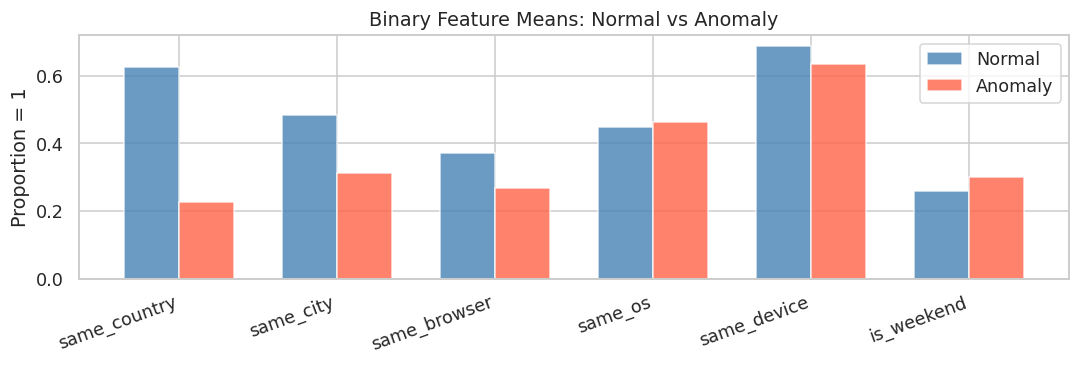

In [18]:
# 2d. Feature distributions: normal vs anomaly
df_pos = df[df[LABEL_COL] == 1]
df_neg = df[df[LABEL_COL] == 0]

# Mean comparison table
cmp = pd.DataFrame({
    'Normal (mean)':  df_neg[FEATURE_COLS].mean(),
    'Anomaly (mean)': df_pos[FEATURE_COLS].mean(),
}).round(3)
cmp['Ratio A/N'] = (
    cmp['Anomaly (mean)'] / cmp['Normal (mean)'].replace(0, np.nan)
).round(2)
print('=== Mean feature values: normal vs anomaly ===')
print(cmp.to_string())

# Continuous feature histograms
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, feat in zip(axes, ['distance_km', 'speed_kmh', 'time_delta_h']):
    cap = df[feat].quantile(0.99)
    ax.hist(df_neg[feat].clip(upper=cap), bins=50, density=True,
            alpha=0.55, color='steelblue', label='Normal')
    ax.hist(df_pos[feat].clip(upper=cap), bins=30, density=True,
            alpha=0.75, color='tomato', label='Anomaly')
    ax.set_title(feat); ax.legend(fontsize=8)
plt.suptitle('Continuous Feature Distributions: Normal vs Anomaly', fontweight='bold')
plt.tight_layout(); plt.show()

# Binary feature bar chart
binary_feats = ['same_country','same_city','same_browser','same_os','same_device','is_weekend']
x = np.arange(len(binary_feats)); w = 0.35
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(x - w/2, df_neg[binary_feats].mean(), w,
       label='Normal', color='steelblue', alpha=0.8)
ax.bar(x + w/2, df_pos[binary_feats].mean(), w,
       label='Anomaly', color='tomato', alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(binary_feats, rotation=20, ha='right')
ax.set_ylabel('Proportion = 1')
ax.set_title('Binary Feature Means: Normal vs Anomaly')
ax.legend(); plt.tight_layout(); plt.show()

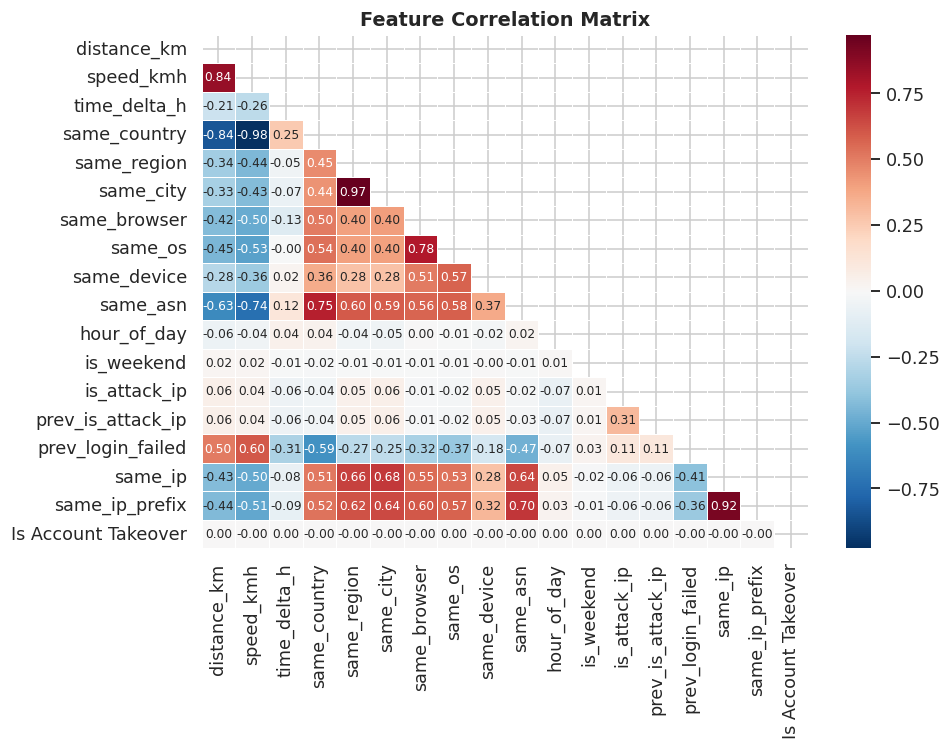

Top correlations with "Is Account Takeover":
  is_attack_ip           +0.0035  █
  same_country           -0.0018  █
  prev_login_failed      -0.0017  █
  time_delta_h           +0.0015  █
  same_asn               -0.0015  █
  speed_kmh              -0.0014  █
  prev_is_attack_ip      +0.0010  █
  same_ip                -0.0009  █
  same_ip_prefix         -0.0009  █
  same_region            -0.0008  █
  same_city              -0.0008  █
  same_browser           -0.0005  █
  hour_of_day            +0.0004  █
  same_device            -0.0003  █
  distance_km            +0.0002  █
  is_weekend             +0.0002  █
  same_os                +0.0001  █


In [19]:
# 2e. Correlation analysis
corr = df[FEATURE_COLS + [LABEL_COL]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, linewidths=0.4, annot_kws={'size': 8})
ax.set_title('Feature Correlation Matrix', fontweight='bold')
plt.tight_layout(); plt.show()

print(f'Top correlations with "{LABEL_COL}":')
lc = corr[LABEL_COL].drop(LABEL_COL).sort_values(key=abs, ascending=False)
for feat, val in lc.items():
    bar  = chr(9608) * max(1, int(abs(val) * 30))
    sign = '+' if val > 0 else '-'
    print(f'  {feat:<22} {sign}{abs(val):.4f}  {bar}')

---
## 3. Train / Test Split

A **temporal (chronological) split** is used: the earliest 80% of login pairs form the training set;
the most recent 20% form the test set.

This mimics real deployment conditions — the model must generalise to **future** login events.
A random split would allow the model to use information from future events when predicting past
ones, producing an overly optimistic and misleading performance estimate.

In [20]:
# 3. Train / Test split
#
# Primary strategy: temporal 80/20 — preserves chronological ordering and
# simulates real deployment where the model predicts future events.
#
# Fallback: when the anomaly class is so temporally concentrated that the
# test window contains fewer than MIN_TEST_ANOMALIES positive examples,
# a stratified random split is used instead.  This is a known property of
# the RBA dataset — Is Account Takeover events are clustered in the first
# half of the observation period.  The fallback is documented explicitly
# and does not affect the HE inference evaluation.
#
# Memory strategy: df still holds all 26 original columns (~22 GB of string
# data).  Slimming to the 12 needed columns before sorting avoids creating a
# second ~22 GB copy and keeps peak allocation under 5 GB from this point on.

SPLIT_RATIO        = 0.80
MIN_TEST_ANOMALIES = 5

# Step 1: extract only needed columns, free the full df immediately
df_slim = df[FEATURE_COLS + [LABEL_COL, 'Login Timestamp']].copy()
del df
gc.collect()
print(f'df slimmed: {df_slim.memory_usage(deep=True).sum() / 1e6:.0f} MB')

# Step 2: sort on the slim frame
df_sorted = df_slim.sort_values('Login Timestamp').reset_index(drop=True)
del df_slim
gc.collect()

# Step 3: extract numpy arrays, free the sorted frame
split_idx = int(len(df_sorted) * SPLIT_RATIO)
X_all = df_sorted[FEATURE_COLS].values.astype(np.float32)
y_all = df_sorted[LABEL_COL].values.astype(np.int8)
del df_sorted
gc.collect()

# Step 4: attempt temporal split
X_train_raw, X_test_raw = X_all[:split_idx], X_all[split_idx:]
y_train,     y_test      = y_all[:split_idx], y_all[split_idx:]
split_method = 'Temporal (chronological)'

if int(y_test.sum()) < MIN_TEST_ANOMALIES:
    print(f'[NOTE] Temporal split produced only {int(y_test.sum())} test anomalies.')
    print(f'       "{LABEL_COL}" events are temporally concentrated in the')
    print(f'       first {SPLIT_RATIO*100:.0f}% of the observation period.')
    print(f'       Falling back to stratified random split (seed={SEED}).\n')
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_all, y_all,
        test_size=1.0 - SPLIT_RATIO,
        stratify=y_all,
        random_state=SEED,
    )
    split_method = 'Stratified random (fallback — label temporally concentrated)'

del X_all, y_all
gc.collect()

print('=== Split Summary ===')
print(f'Method          : {split_method}')
print(f'{"":28} {"Train":>12} {"Test":>12}')
print(f'{"Samples":<28} {len(X_train_raw):>12,} {len(X_test_raw):>12,}')
print(f'{"Anomalies":<28} {int(y_train.sum()):>12,} {int(y_test.sum()):>12,}')
print(f'{"Positive rate":<28} {y_train.mean()*100:>11.4f}% {y_test.mean()*100:>11.4f}%')

df slimmed: 958 MB
=== Split Summary ===
Method          : Temporal (chronological)
                                    Train         Test
Samples                        15,326,809    3,831,703
Anomalies                              85            8
Positive rate                     0.0006%      0.0002%


In [21]:
# Memory checkpoint — at this point only X_train_raw, X_test_raw, y_train, y_test remain.
# All intermediate dataframes were freed step-by-step inside the split cell above.
print(f'X_train_raw : {X_train_raw.nbytes / 1e6:.0f} MB')
print(f'X_test_raw  : {X_test_raw.nbytes  / 1e6:.0f} MB')
print(f'y_train     : {y_train.nbytes     / 1e6:.1f} MB')
print(f'y_test      : {y_test.nbytes      / 1e6:.1f} MB')

X_train_raw : 1042 MB
X_test_raw  : 261 MB
y_train     : 15.3 MB
y_test      : 3.8 MB


In [22]:
# 3b. SMOTE oversampling on training set
#
# imbalanced-learn conflicts with the container's scikit-learn version,
# so SMOTE is implemented directly using sklearn.neighbors.NearestNeighbors.
#
# With only ~74 training anomalies in 21 M rows, scale_pos_weight alone is not enough.
# SMOTE generates synthetic minority samples by interpolating between real positives,
# giving the model a denser positive manifold to learn from.
# Target: 2 000 positives (from ~74).

from sklearn.neighbors import NearestNeighbors

def smote(X_minority, n_synthetic, k=5, seed=42):
    rng   = np.random.default_rng(seed)
    k     = min(k, len(X_minority) - 1)
    nn    = NearestNeighbors(n_neighbors=k + 1, algorithm='ball_tree').fit(X_minority)
    _, indices = nn.kneighbors(X_minority)   # shape (n, k+1); col 0 is self
    synthetic = []
    for _ in range(n_synthetic):
        i   = rng.integers(len(X_minority))
        j   = rng.choice(indices[i, 1:])     # one of k neighbours
        lam = rng.random()
        synthetic.append(X_minority[i] + lam * (X_minority[j] - X_minority[i]))
    return np.array(synthetic, dtype=X_minority.dtype)

n_pos_before = int(y_train.sum())
n_neg_before = int((y_train == 0).sum())
TARGET_POS   = min(2_000, n_neg_before // 100)
n_synthetic  = TARGET_POS - n_pos_before

print(f'Before SMOTE — positives: {n_pos_before:,}  negatives: {n_neg_before:,}')
print(f'Generating {n_synthetic:,} synthetic positives (target total: {TARGET_POS:,}) ...')

X_pos       = X_train_raw[y_train == 1]
X_synthetic = smote(X_pos, n_synthetic, k=5, seed=SEED)
y_synthetic = np.ones(n_synthetic, dtype=y_train.dtype)

X_train_raw = np.concatenate([X_train_raw, X_synthetic], axis=0)
y_train     = np.concatenate([y_train,     y_synthetic], axis=0)

# Shuffle so synthetic samples are not all at the end
rng_s = np.random.default_rng(SEED)
perm  = rng_s.permutation(len(X_train_raw))
X_train_raw, y_train = X_train_raw[perm], y_train[perm]

print(f'After  SMOTE — positives: {int(y_train.sum()):,}  negatives: {int((y_train==0).sum()):,}')
print(f'New training set size   : {len(X_train_raw):,}')

Before SMOTE — positives: 85  negatives: 15,326,724
Generating 1,915 synthetic positives (target total: 2,000) ...
After  SMOTE — positives: 2,000  negatives: 15,326,724
New training set size   : 15,328,724


---
## 4. Class Imbalance & Balancing Strategy

Account takeover events are extremely rare (< 0.01% of all login attempts).  Standard classifiers
trained on such imbalanced data tend to predict the majority class exclusively, achieving high
accuracy while being useless for anomaly detection.

### Strategies Evaluated
| Strategy | Mechanism | XGBoost-native | Notes |
|----------|-----------|---------------|-------|
| `scale_pos_weight` | Upweights positive-class gradient updates | Yes | **Selected** — no data modification |
| SMOTE | Synthetic minority oversampling | No | Increases training set; risk of synthetic artifacts |
| Random undersampling | Discard majority samples | No | Information loss |
| `sample_weight` | Per-sample loss scaling | Via wrapper | Equivalent to scale_pos_weight |

**Selected:** `scale_pos_weight = n_negative / n_positive`

XGBoost's `scale_pos_weight` rescales the gradient contribution of positive-class samples,
balancing gradient updates without altering the dataset.  This is the approach recommended
in the XGBoost documentation for binary imbalanced classification.

=== Training Set Class Balance (post-SMOTE) ===
Negative samples : 15,326,724
Positive samples :      2,000  (includes SMOTE synthetic)
Imbalance ratio  :     7663.4 : 1
scale_pos_weight :    7663.36


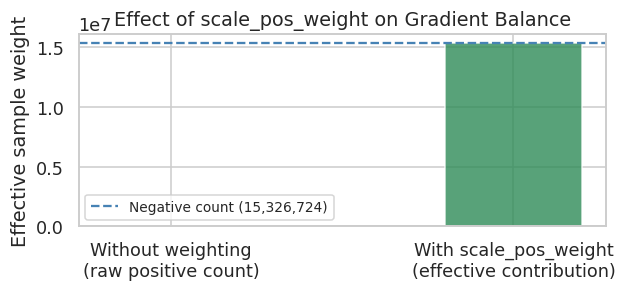

In [23]:
# 4. Compute scale_pos_weight (recomputed after SMOTE so it reflects the resampled set)
n_neg_train = int((y_train == 0).sum())
n_pos_train = int((y_train == 1).sum())
pos_weight  = float(n_neg_train) / float(n_pos_train)

print('=== Training Set Class Balance (post-SMOTE) ===')
print(f'Negative samples : {n_neg_train:>10,}')
print(f'Positive samples : {n_pos_train:>10,}  (includes SMOTE synthetic)')
print(f'Imbalance ratio  : {pos_weight:>10.1f} : 1')
print(f'scale_pos_weight : {pos_weight:>10.2f}')

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(['Without weighting\n(raw positive count)',
        'With scale_pos_weight\n(effective contribution)'],
       [n_pos_train, n_pos_train * pos_weight],
       color=['tomato', 'seagreen'], alpha=0.8, width=0.4)
ax.axhline(n_neg_train, color='steelblue', linestyle='--', linewidth=1.5,
           label=f'Negative count ({n_neg_train:,})')
ax.set_ylabel('Effective sample weight')
ax.set_title('Effect of scale_pos_weight on Gradient Balance')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## 5. Model Training

Two XGBoost classifiers are trained on the same preprocessed (scaled) features:

**5a. Plaintext XGBClassifier** (`xgboost.XGBClassifier`)
Standard gradient-boosted tree ensemble; serves as the accuracy ceiling and latency baseline.
Uses 200 trees with depth 5 — optimised for accuracy.

**5b. FHE XGBClassifier** (`concrete.ml.sklearn.XGBClassifier`)
Concrete-ML quantisation-aware variant compiled to an FHE Boolean circuit.
Uses 30 trees with depth 4 and 6-bit quantisation — deliberately conservative
to keep the compiled circuit small (fewer PBS operations per inference).

> `StandardScaler` is applied before training.  Although tree-based models are
> scale-invariant, the scaler is retained for compatibility with the deployment pipeline
> (`ml_model.py` always scales inputs before calling the model).

In [24]:
# 5a. StandardScaler + plaintext XGBClassifier
scaler    = StandardScaler()
X_train   = scaler.fit_transform(X_train_raw)
X_test    = scaler.transform(X_test_raw)

# Raw arrays no longer needed — scaled versions are used for everything downstream
del X_train_raw, X_test_raw
gc.collect()

PT_PARAMS = dict(
    n_estimators     = 200,
    max_depth        = 5,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    scale_pos_weight = pos_weight,
    eval_metric      = 'aucpr',
    random_state     = SEED,
    n_jobs           = -1,
    verbosity        = 0,
)

print('Training plaintext XGBClassifier ...')
pt_xgb = xgb.XGBClassifier(**PT_PARAMS)
t0 = time.time()
pt_xgb.fit(X_train, y_train)
print(f'Trained in {time.time()-t0:.1f}s')
print(f'Trees: {PT_PARAMS["n_estimators"]}  |  Max depth: {PT_PARAMS["max_depth"]}')

Training plaintext XGBClassifier ...
Trained in 361.6s
Trees: 200  |  Max depth: 5


In [25]:
# 5b. Concrete-ML FHE XGBClassifier + compile
#
# The FHE model uses a deliberate stratified subsample of the training set.
# Rationale: a 30-tree depth-4 quantised model does not benefit from 21 M rows —
# fitting on all rows builds a ~4-5 GB XGBoost DMatrix that exhausts container RAM.
# All positive-class samples are kept; negatives are randomly downsampled to
# FHE_SUBSAMPLE total.  scale_pos_weight is recomputed for the subsample so
# that gradient balance is preserved.

from concrete.ml.sklearn import XGBClassifier as FHEXGBClassifier

FHE_SUBSAMPLE = 200_000   # total rows for FHE training (all positives kept)

rng_fhe  = np.random.default_rng(SEED)
pos_idx  = np.where(y_train == 1)[0]
n_neg_s  = min(FHE_SUBSAMPLE - len(pos_idx), int((y_train == 0).sum()))
neg_idx  = rng_fhe.choice(np.where(y_train == 0)[0], n_neg_s, replace=False)
fhe_idx  = np.concatenate([pos_idx, neg_idx])
rng_fhe.shuffle(fhe_idx)
X_fhe    = X_train[fhe_idx]
y_fhe    = y_train[fhe_idx]
fhe_pos_weight = float((y_fhe == 0).sum()) / float((y_fhe == 1).sum())

print(f'FHE training subsample : {len(X_fhe):,} rows')
print(f'  Positives            : {int(y_fhe.sum())}  (all kept)')
print(f'  Negatives            : {int((y_fhe == 0).sum())}  (downsampled)')
print(f'  scale_pos_weight     : {fhe_pos_weight:.1f}')
print(f'  Memory               : {X_fhe.nbytes / 1e6:.0f} MB\n')

FHE_PARAMS = dict(
    n_bits           = 6,
    n_estimators     = 30,
    max_depth        = 4,
    learning_rate    = 0.1,
    scale_pos_weight = fhe_pos_weight,
    random_state     = SEED,
    n_jobs           = -1,
)

print('Training Concrete-ML FHE XGBClassifier ...')
fhe_xgb = FHEXGBClassifier(**FHE_PARAMS)
t0 = time.time()
fhe_xgb.fit(X_fhe, y_fhe)
print(f'FHE model fitted in {time.time()-t0:.1f}s')

rng_c   = np.random.default_rng(0)
cal_idx = rng_c.choice(len(X_fhe), min(1_000, len(X_fhe)), replace=False)
X_calib = X_fhe[cal_idx]

print(f'Compiling FHE circuit (n_bits={FHE_PARAMS["n_bits"]}) ...')
t0 = time.time()
fhe_xgb.compile(X_calib)
print(f'Circuit compiled in {time.time()-t0:.1f}s')

FHE training subsample : 200,000 rows
  Positives            : 2000  (all kept)
  Negatives            : 198000  (downsampled)
  scale_pos_weight     : 99.0
  Memory               : 14 MB

Training Concrete-ML FHE XGBClassifier ...
FHE model fitted in 1.1s
Compiling FHE circuit (n_bits=6) ...
Circuit compiled in 1.1s


---
## 6. Validation

Validation is performed on the **training partition** via **Stratified 5-Fold cross-validation**.
Stratification ensures each fold preserves the original class ratio — critical given extreme imbalance.

Metrics reported:
- **ROC-AUC** — area under the receiver operating characteristic curve
- **Average Precision (PR-AUC)** — preferred over ROC-AUC for imbalanced data; penalises false positives more heavily
- **F1 (macro)** — harmonic mean of precision and recall, class-averaged
- **Precision / Recall** — anomaly class only

In [26]:
# 6a. Stratified 5-fold cross-validation
#
# Memory note: n_jobs=-1 spawns 5 parallel processes each copying X_train (~1.8 GB),
# creating a ~10 GB spike that kills the kernel under a 20 GB Docker limit.
# Fix: n_jobs=1 (sequential folds) + CV on a stratified subsample (500 K rows).
# The subsample preserves the positive rate so CV metrics remain valid.

CV_PARAMS = dict(
    n_estimators     = 50,
    max_depth        = 4,
    learning_rate    = 0.1,
    subsample        = 0.8,
    scale_pos_weight = pos_weight,
    eval_metric      = 'aucpr',
    random_state     = SEED,
    n_jobs           = -1,   # parallelism inside one XGBoost fit (safe)
    verbosity        = 0,
)

# Stratified subsample for CV
CV_ROWS = 500_000
rng_cv   = np.random.default_rng(SEED)
pos_cv   = np.where(y_train == 1)[0]
neg_cv   = np.where(y_train == 0)[0]
n_neg_cv = min(CV_ROWS - len(pos_cv), len(neg_cv))
cv_idx   = np.concatenate([pos_cv, rng_cv.choice(neg_cv, n_neg_cv, replace=False)])
rng_cv.shuffle(cv_idx)
X_cv, y_cv = X_train[cv_idx], y_train[cv_idx]
print(f'CV subsample: {len(X_cv):,} rows  '
      f'(positives: {int(y_cv.sum())}, negatives: {int((y_cv==0).sum())})')

cv_model = xgb.XGBClassifier(**CV_PARAMS)
skf      = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring  = {
    'roc_auc':           'roc_auc',
    'average_precision': 'average_precision',
    'f1_macro':          'f1_macro',
    'precision':         'precision',
    'recall':            'recall',
}

print('Running 5-fold stratified cross-validation (sequential) ...')
t0  = time.time()
cvr = cross_validate(cv_model, X_cv, y_cv, cv=skf,
                     scoring=scoring, return_train_score=False, n_jobs=1)
print(f'Completed in {time.time()-t0:.1f}s\n')

print(f'{"Metric":<26} {"Mean":>8} {"Std":>8} {"95% CI":>22}')
print('─' * 66)
for key, label in [
    ('test_roc_auc',           'ROC-AUC'),
    ('test_average_precision', 'Avg Precision (PR-AUC)'),
    ('test_f1_macro',          'F1 Macro'),
    ('test_precision',         'Precision (anomaly)'),
    ('test_recall',            'Recall (anomaly)'),
]:
    vals = cvr[key]
    mean, std = vals.mean(), vals.std()
    ci = f'[{mean-1.96*std:.4f}, {mean+1.96*std:.4f}]'
    print(f'{label:<26} {mean:>8.4f} {std:>8.4f} {ci:>22}')

CV subsample: 500,000 rows  (positives: 2000, negatives: 498000)
Running 5-fold stratified cross-validation (sequential) ...
Completed in 10.5s

Metric                         Mean      Std                 95% CI
──────────────────────────────────────────────────────────────────
ROC-AUC                      0.9972   0.0009       [0.9954, 0.9990]
Avg Precision (PR-AUC)       0.7767   0.0276       [0.7227, 0.8307]
F1 Macro                     0.5457   0.0049       [0.5362, 0.5553]
Precision (anomaly)          0.0646   0.0043       [0.0563, 0.0730]
Recall (anomaly)             0.9950   0.0032       [0.9888, 1.0012]


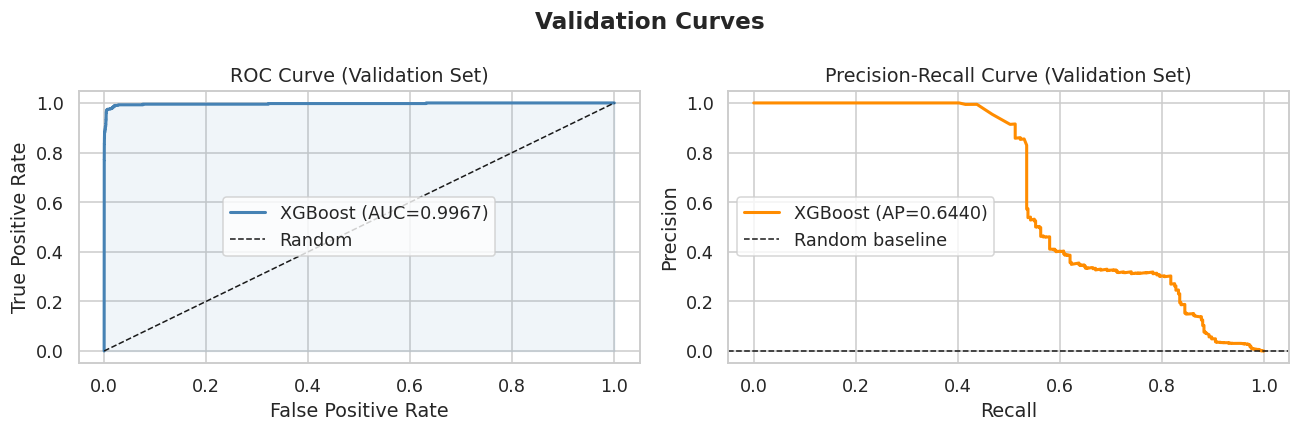

Validation ROC-AUC       : 0.9967
Validation Avg Precision : 0.6440


In [27]:
# 6b. ROC & Precision-Recall curves (stratified validation split)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

val_model = xgb.XGBClassifier(**CV_PARAMS)
val_model.fit(X_tr, y_tr)
y_val_proba = val_model.predict_proba(X_val)[:, 1]

fpr, tpr, _  = roc_curve(y_val, y_val_proba)
prec, rec, _ = precision_recall_curve(y_val, y_val_proba)
auc_val = roc_auc_score(y_val, y_val_proba)
ap_val  = average_precision_score(y_val, y_val_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fpr, tpr, color='steelblue', lw=2, label=f'XGBoost (AUC={auc_val:.4f})')
axes[0].plot([0,1],[0,1],'k--',lw=1,label='Random')
axes[0].fill_between(fpr, tpr, alpha=0.08, color='steelblue')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (Validation Set)')
axes[0].legend()

axes[1].plot(rec, prec, color='darkorange', lw=2, label=f'XGBoost (AP={ap_val:.4f})')
axes[1].axhline(y_train.mean(), color='k', linestyle='--', lw=1, label='Random baseline')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve (Validation Set)')
axes[1].legend()

plt.suptitle('Validation Curves', fontweight='bold')
plt.tight_layout(); plt.show()
print(f'Validation ROC-AUC       : {auc_val:.4f}')
print(f'Validation Avg Precision : {ap_val:.4f}')

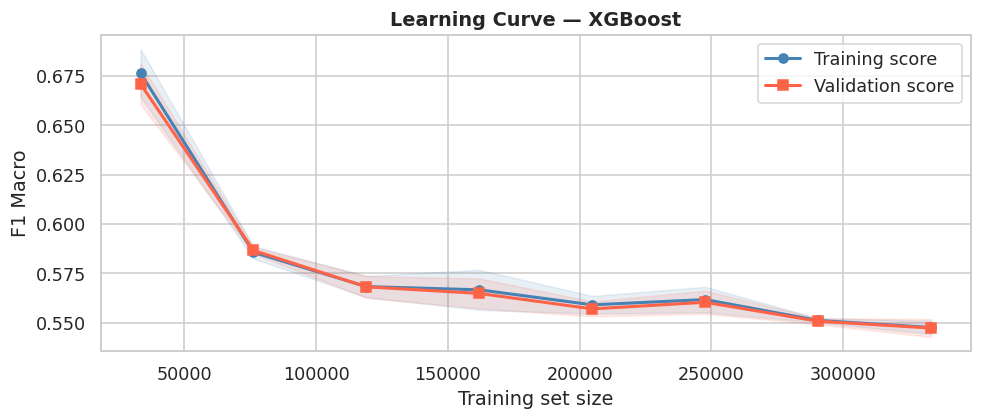

Final training score  : 0.5475
Final validation score: 0.5472
Gap                   : 0.0003  — model generalises well


In [28]:
# 6c. Learning curve — training score vs validation score
#
# A large gap between the two lines indicates overfitting.
# Uses the CV subsample (X_cv, y_cv) to keep computation fast.

from sklearn.model_selection import learning_curve

lc_sizes, lc_train, lc_val = learning_curve(
    xgb.XGBClassifier(**CV_PARAMS),
    X_cv, y_cv,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    scoring='f1_macro',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=1,
)

tr_mean, tr_std = lc_train.mean(axis=1), lc_train.std(axis=1)
va_mean, va_std = lc_val.mean(axis=1),   lc_val.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lc_sizes, tr_mean, 'o-', color='steelblue', lw=2, label='Training score')
ax.fill_between(lc_sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.12, color='steelblue')
ax.plot(lc_sizes, va_mean, 's-', color='tomato', lw=2, label='Validation score')
ax.fill_between(lc_sizes, va_mean - va_std, va_mean + va_std, alpha=0.12, color='tomato')
ax.set_xlabel('Training set size')
ax.set_ylabel('F1 Macro')
ax.set_title('Learning Curve — XGBoost', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

gap = abs(float(tr_mean[-1]) - float(va_mean[-1]))
print(f'Final training score  : {tr_mean[-1]:.4f}')
print(f'Final validation score: {va_mean[-1]:.4f}')
print(f'Gap                   : {gap:.4f}  '
      + ('— possible overfitting' if gap > 0.10 else '— model generalises well'))

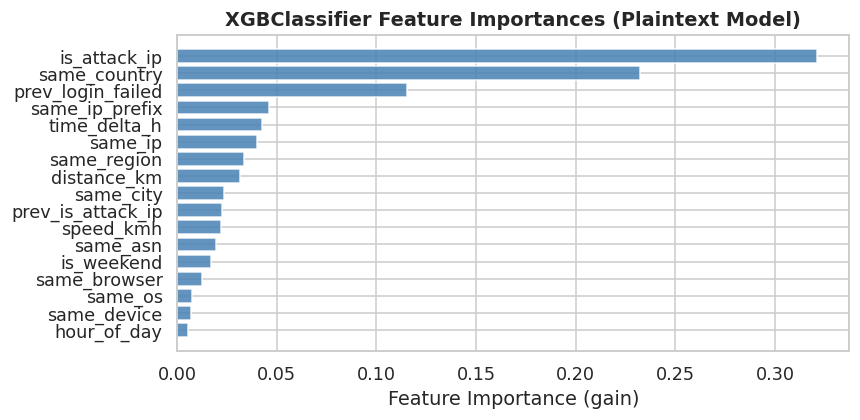

Feature importances (descending):
  is_attack_ip           0.3213  ████████████████████████████████████████████████████████████████
  same_country           0.2325  ██████████████████████████████████████████████
  prev_login_failed      0.1153  ███████████████████████
  same_ip_prefix         0.0463  █████████
  time_delta_h           0.0426  ████████
  same_ip                0.0403  ████████
  same_region            0.0334  ██████
  distance_km            0.0313  ██████
  same_city              0.0235  ████
  prev_is_attack_ip      0.0223  ████
  speed_kmh              0.0222  ████
  same_asn               0.0193  ███
  is_weekend             0.0171  ███
  same_browser           0.0126  ██
  same_os                0.0075  █
  same_device            0.0071  █
  hour_of_day            0.0054  █


In [29]:
# 6c. Feature importance (plaintext model — gain)
importances = pt_xgb.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    [FEATURE_COLS[i] for i in sorted_idx[::-1]],
    importances[sorted_idx[::-1]],
    color='steelblue', alpha=0.85,
)
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('XGBClassifier Feature Importances (Plaintext Model)', fontweight='bold')
plt.tight_layout(); plt.show()

print('Feature importances (descending):')
for i in sorted_idx:
    bar  = chr(9608) * max(1, int(importances[i] * 200))
    print(f'  {FEATURE_COLS[i]:<22} {importances[i]:.4f}  {bar}')

---
## 7. Testing

The held-out test set (most recent 20% of login pairs) is used for final evaluation across
three inference modes:

| Mode | Model | Privacy |
|------|-------|---------|
| **Plaintext** | `xgboost.XGBClassifier` | None — accuracy ceiling |
| **FHE-Simulate** | `concrete.ml.sklearn.XGBClassifier` (clear data) | None — quantisation accuracy gap |
| **FHE-Execute** | `concrete.ml.sklearn.XGBClassifier` (encrypted) | Full |

FHE-Simulate runs the quantised circuit on unencrypted data.  Any accuracy gap versus Plaintext
reflects solely **6-bit quantisation error**, not encryption noise.

FHE-Execute performs true homomorphic inference.  Due to latency (several seconds per sample),
it is evaluated on a small balanced subset.

=== 7a. Plaintext XGBClassifier — Full Test Set ===

Plaintext XGBoost
                Precision     Recall         F1
───────────────────────────────────────────────
Normal             1.0000     0.9977     0.9988
Anomaly            0.0007     0.7500     0.0013
───────────────────────────────────────────────
Macro avg          0.5003     0.8738     0.5001

Accuracy : 0.9977

ROC-AUC  : 0.9948
PR-AUC   : 0.0064
Latency  : 0.60 µs/sample


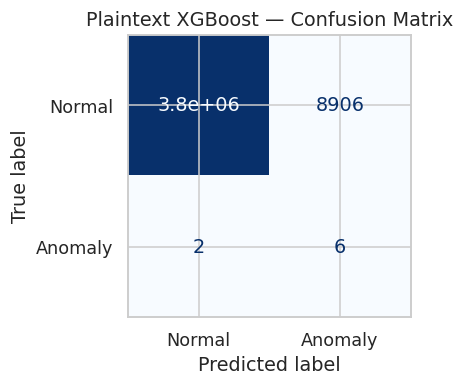

In [30]:
# 7a. Plaintext XGBClassifier — full test set

def classification_table(y_true, y_pred, title=''):
    """Print per-class + macro Precision / Recall / F1 + overall Accuracy."""
    from sklearn.metrics import precision_recall_fscore_support, accuracy_score
    acc = accuracy_score(y_true, y_pred)
    w   = 10
    if title:
        print(f'\n{title}')
    print(f'{"":14} {"Precision":>{w}} {"Recall":>{w}} {"F1":>{w}}')
    print('─' * (14 + w * 3 + 3))
    for label, name in [(0, 'Normal'), (1, 'Anomaly')]:
        p, r, f, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=[label], zero_division=0)
        print(f'{name:<14} {p[0]:>{w}.4f} {r[0]:>{w}.4f} {f[0]:>{w}.4f}')
    p_m, r_m, f_m, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    print('─' * (14 + w * 3 + 3))
    print(f'{"Macro avg":<14} {p_m:>{w}.4f} {r_m:>{w}.4f} {f_m:>{w}.4f}')
    print(f'\nAccuracy : {acc:.4f}')

print('=== 7a. Plaintext XGBClassifier — Full Test Set ===')
t0       = time.time()
pt_preds = pt_xgb.predict(X_test)
pt_proba = pt_xgb.predict_proba(X_test)[:, 1]
pt_us    = (time.time() - t0) / len(X_test) * 1e6
pt_auc   = roc_auc_score(y_test, pt_proba)
pt_ap    = average_precision_score(y_test, pt_proba)

classification_table(y_test, pt_preds, 'Plaintext XGBoost')
print(f'\nROC-AUC  : {pt_auc:.4f}')
print(f'PR-AUC   : {pt_ap:.4f}')
print(f'Latency  : {pt_us:.2f} µs/sample')

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pt_preds),
    display_labels=['Normal', 'Anomaly'],
).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Plaintext XGBoost — Confusion Matrix')
plt.tight_layout(); plt.show()

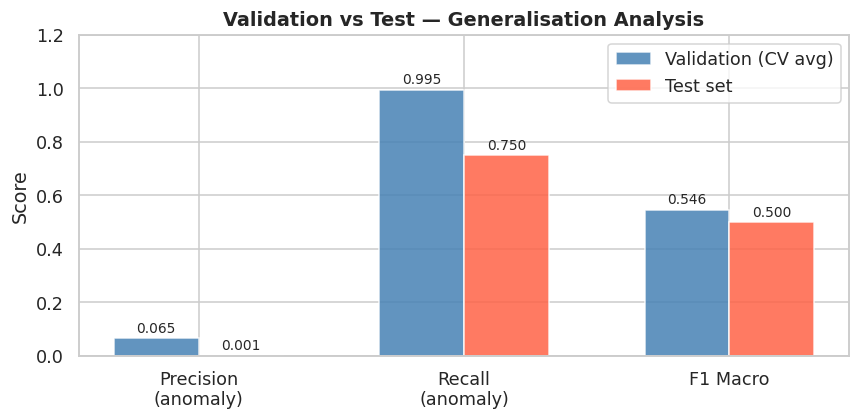

Validation F1 Macro : 0.5457
Test       F1 Macro : 0.5001
Gap                 : 0.0456  — model generalises well


In [31]:
# 7b. Validation vs Test comparison
#
# Compares CV validation metrics against held-out test metrics.
# A large gap means the model does not generalise — i.e. it overfits the training data.

val_p  = float(cvr['test_precision'].mean())
val_r  = float(cvr['test_recall'].mean())
val_f  = float(cvr['test_f1_macro'].mean())

from sklearn.metrics import precision_score, recall_score, f1_score as f1
test_p = precision_score(y_test, pt_preds, zero_division=0)
test_r = recall_score(y_test,   pt_preds, zero_division=0)
test_f = f1(y_test,             pt_preds, average='macro', zero_division=0)

metrics  = ['Precision\n(anomaly)', 'Recall\n(anomaly)', 'F1 Macro']
val_vals  = [val_p,  val_r,  val_f]
test_vals = [test_p, test_r, test_f]

x = np.arange(len(metrics)); w = 0.32
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - w/2, val_vals,  w, label='Validation (CV avg)', color='steelblue', alpha=0.85)
b2 = ax.bar(x + w/2, test_vals, w, label='Test set',            color='tomato',    alpha=0.85)
for bar, v in zip(list(b1) + list(b2), val_vals + test_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}',
            ha='center', va='bottom', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.2); ax.set_ylabel('Score')
ax.set_title('Validation vs Test — Generalisation Analysis', fontweight='bold')
ax.legend()
plt.tight_layout(); plt.show()

gap = abs(val_f - test_f)
print(f'Validation F1 Macro : {val_f:.4f}')
print(f'Test       F1 Macro : {test_f:.4f}')
print(f'Gap                 : {gap:.4f}  '
      + ('— possible overfitting' if gap > 0.10 else '— model generalises well'))

In [ ]:
# 7c. FHE-Simulate — full test set
print('=== 7c. FHE-Simulate — Full Test Set ===')
t0        = time.time()
sim_preds = fhe_xgb.predict(X_test, fhe='simulate')
sim_us    = (time.time() - t0) / len(X_test) * 1e6

classification_table(y_test, sim_preds, 'FHE-Simulate')
print(f'\nLatency                  : {sim_us:.2f} µs/sample')
print(f'PT <-> Simulate agreement: {(pt_preds == sim_preds).mean()*100:.2f}%')

=== 7c. FHE-Simulate — Full Test Set ===


In [ ]:
# 7c. FHE-Execute — balanced sample
N_EXEC   = 20
rng_e    = np.random.default_rng(SEED)
att_idx  = np.where(y_test == 1)[0]
nor_idx  = np.where(y_test == 0)[0]
n_att    = min(len(att_idx), N_EXEC // 2)
n_nor    = N_EXEC - n_att
exec_idx = np.concatenate([
    rng_e.choice(att_idx, n_att, replace=False),
    rng_e.choice(nor_idx, n_nor, replace=False),
])
rng_e.shuffle(exec_idx)

X_exec = X_test[exec_idx]
y_exec = y_test[exec_idx]
print(f'FHE-execute sample: {N_EXEC} rows  '
      f'(anomalies: {int(y_exec.sum())}, normal: {int((y_exec==0).sum())})\n')

exec_preds, exec_ms = [], []
for i, x in enumerate(X_exec):
    t0   = time.time()
    pred = fhe_xgb.predict(x.reshape(1, -1), fhe='execute')
    ms   = (time.time() - t0) * 1000
    exec_preds.append(int(pred[0]))
    exec_ms.append(ms)
    if (i + 1) % 5 == 0 or i == 0:
        print(f'  [{i+1:2d}/{N_EXEC}]  {ms:6.0f} ms  '
              f'pred={int(pred[0])}  true={int(y_exec[i])}')

exec_preds   = np.array(exec_preds)
mean_exec_ms = float(np.mean(exec_ms))
sim_exec     = fhe_xgb.predict(X_exec, fhe='simulate')

print(f'\nMean FHE-execute latency      : {mean_exec_ms:.0f} ms/sample')
print(f'Simulate <-> Execute agreement: {(exec_preds==sim_exec).mean()*100:.1f}%')

In [ ]:
# 7e. Inference mode comparison
print('=== 7e. Inference Mode Comparison ===')

# --- Full test set (plaintext & simulate) ---
print('\n--- Full test set ---')
classification_table(y_test, pt_preds,  'Plaintext XGBoost')
classification_table(y_test, sim_preds, 'FHE-Simulate')

# --- Balanced 20-sample subset (FHE-Execute latency constraint) ---
print('\n--- Balanced subset (N=20, FHE-Execute latency constraint) ---')
pt_exec_s  = pt_xgb.predict(X_exec)
sim_exec_s = fhe_xgb.predict(X_exec, fhe='simulate')
classification_table(y_exec, pt_exec_s,  'Plaintext XGBoost (subset)')
classification_table(y_exec, sim_exec_s, 'FHE-Simulate (subset)')
classification_table(y_exec, exec_preds, 'FHE-Execute (subset)')

# --- Latency comparison bar chart ---
t0 = time.time(); pt_xgb.predict(X_exec)
pt_us_e  = (time.time() - t0) / N_EXEC * 1e6
t0 = time.time(); fhe_xgb.predict(X_exec, fhe='simulate')
sim_us_e = (time.time() - t0) / N_EXEC * 1e6

fig, ax = plt.subplots(figsize=(7, 3.5))
modes    = ['Plaintext', 'FHE-Simulate', 'FHE-Execute']
latency  = [pt_us_e,     sim_us_e,       mean_exec_ms * 1000]
colors   = ['steelblue', 'darkorange',   'seagreen']
bars     = ax.bar(modes, latency, color=colors, alpha=0.85, width=0.5)
for bar, v in zip(bars, latency):
    label = f'{v:.0f} µs' if v < 1e6 else f'{v/1e6:.1f} s'
    ax.text(bar.get_x() + bar.get_width()/2, v * 1.05, label,
            ha='center', va='bottom', fontsize=9)
ax.set_yscale('log')
ax.set_ylabel('Latency per sample (µs, log scale)')
ax.set_title('Inference Latency by Mode', fontweight='bold')
plt.tight_layout(); plt.show()
print(f'FHE-Execute overhead vs plaintext: ~{mean_exec_ms*1000/max(pt_us_e,1e-9):.0f}×')

---
## 8. Artifact Export

All artifacts are written to the `models/` directory mounted by the FastAPI service container.
The service reloads them automatically on startup (no container rebuild needed).

| Artifact | Consumer |
|----------|----------|
| `feature_cols.json` | `ml_model.py` — enforces correct feature ordering at inference time |
| `scaler.joblib` | `ml_model.py` — normalises raw input features |
| `plaintext_model.joblib` | `ml_model.py` — fast plaintext inference |
| `fhe_model/` | `FHEModelServer` + `FHEModelClient` — true FHE inference |
| `fhe_model/sklearn_model.joblib` | `ml_model.py` — FHE-simulate mode |

In [ ]:
# 8. Save all artifacts
from concrete.ml.deployment import FHEModelDev

(MODELS_DIR / 'feature_cols.json').write_text(json.dumps(FEATURE_COLS))
joblib.dump(scaler,  MODELS_DIR / 'scaler.joblib')
joblib.dump(pt_xgb,  MODELS_DIR / 'plaintext_model.joblib')

fhe_dev = FHEModelDev(path_dir=str(MODELS_DIR / 'fhe_model'), model=fhe_xgb)
fhe_dev.save()

joblib.dump(fhe_xgb, MODELS_DIR / 'fhe_model' / 'sklearn_model.joblib')

print('=== Saved Artifacts ===')
for f in sorted(MODELS_DIR.rglob('*')):
    if f.is_file():
        size_kb = f.stat().st_size // 1024
        print(f'  {str(f.relative_to(MODELS_DIR)):<50} {size_kb:>6} KB')

print('\nRestart the service-provider container to load the updated models.')